# Naive Bayes

## ¿Cuál es el objetivo de Naive Bayes?

El objetivo de **Naive Bayes** es clasificar una observación calculando la **probabilidad de que pertenezca a cada clase**, y asignándole la clase con mayor probabilidad.

Se basa en el **Teorema de Bayes**, que nos permite calcular probabilidades condicionales "al revés": en lugar de preguntarnos "dado que es clase $c$, ¿qué datos esperamos?", respondemos "dado estos datos, ¿qué clase es más probable?"

$$
\hat{y} = \arg\max_c \ P(y = c \ | \ \mathbf{x})
$$

Donde:

- $\hat{y}$: clase predicha.
- $P(y = c \ | \ \mathbf{x})$: probabilidad **posterior** de la clase $c$ dado el vector de features $\mathbf{x}$.

El adjetivo **"Naive"** (ingenuo) viene de la suposición clave del algoritmo: que **todas las features son independientes entre sí** dada la clase. Aunque esta suposición rara vez es cierta en la práctica, el algoritmo funciona sorprendentemente bien en muchos problemas reales.

Ventajas clave:
- **Rápido** para entrenar y predecir.
- Funciona bien con **pocos datos**.
- Escalable a **muchas features** (ej: clasificación de texto).
- No necesita descenso de gradiente: los parámetros se calculan directamente de los datos.

**Supongamos un conjunto de datos simples**

Imaginemos que queremos clasificar si una fruta es una **manzana** (0) o una **naranja** (1) según dos características: peso (gramos) y diámetro (cm).

| Peso (g) | Diámetro (cm) | Fruta    |
|----------|---------------|----------|
| 130      | 7.0           | Manzana (0) |
| 140      | 7.2           | Manzana (0) |
| 150      | 7.4           | Manzana (0) |
| 160      | 7.6           | Manzana (0) |
| 170      | 8.0           | Naranja (1) |
| 180      | 8.5           | Naranja (1) |
| 190      | 9.0           | Naranja (1) |
| 200      | 9.2           | Naranja (1) |

Si aparece una nueva fruta con peso = 165 g y diámetro = 7.8 cm, ¿qué es? Naive Bayes calcula la probabilidad de cada clase y elige la más probable.

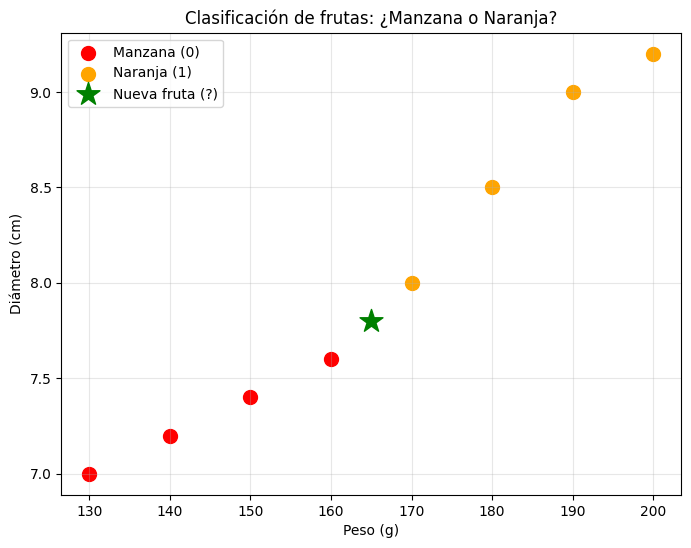

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

# Datos de entrenamiento
pesos = np.array([130, 140, 150, 160, 170, 180, 190, 200])
diametros = np.array([7.0, 7.2, 7.4, 7.6, 8.0, 8.5, 9.0, 9.2])
clases = np.array([0, 0, 0, 0, 1, 1, 1, 1])

# Nuevo punto
x_new = [165, 7.8]

plt.figure(figsize=(8, 6))
plt.scatter(pesos[clases == 0], diametros[clases == 0], color='red', label='Manzana (0)', s=100)
plt.scatter(pesos[clases == 1], diametros[clases == 1], color='orange', label='Naranja (1)', s=100)
plt.scatter(x_new[0], x_new[1], color='green', marker='*', s=300, label='Nueva fruta (?)')
plt.xlabel('Peso (g)')
plt.ylabel('Diámetro (cm)')
plt.title('Clasificación de frutas: ¿Manzana o Naranja?')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## ¿Cómo decide Naive Bayes la clase?

Naive Bayes no mide distancias (como KNN) ni ajusta pesos (como Regresión Logística). En su lugar, usa **probabilidades**.

La pregunta fundamental es: **dado lo que observo ($\mathbf{x}$), ¿cuál es la probabilidad de cada clase?**

Para responderla, necesitamos el **Teorema de Bayes**, que conecta lo que sabemos (los datos de entrenamiento) con lo que queremos saber (la clase de un nuevo punto).

## Demostración Matemática

### Paso 1: El Teorema de Bayes

El Teorema de Bayes establece:

$$
P(y = c \ | \ \mathbf{x}) = \frac{P(\mathbf{x} \ | \ y = c) \cdot P(y = c)}{P(\mathbf{x})}
$$

Donde:

| Término | Nombre | Significado |
|---------|--------|-------------|
| $P(y = c \ \| \ \mathbf{x})$ | **Posterior** | Prob. de la clase $c$ dado los datos (lo que queremos) |
| $P(\mathbf{x} \ \| \ y = c)$ | **Likelihood** | Prob. de observar estos datos si la clase es $c$ |
| $P(y = c)$ | **Prior** | Prob. de la clase $c$ antes de ver los datos |
| $P(\mathbf{x})$ | **Evidencia** | Prob. total de los datos (constante para todas las clases) |

Como $P(\mathbf{x})$ es el mismo para todas las clases, podemos ignorarlo y simplemente comparar los numeradores:

$$
\hat{y} = \arg\max_c \ P(\mathbf{x} \ | \ y = c) \cdot P(y = c)
$$

Es decir: **posterior $\propto$ likelihood $\times$ prior**.

### Paso 2: La suposición "Naive" (independencia condicional)

El likelihood $P(\mathbf{x} \ | \ y = c)$ para un vector $\mathbf{x} = (x_1, x_2, \dots, x_n)$ es difícil de estimar porque necesitaríamos la distribución conjunta de todas las features.

La suposición **naive** simplifica esto: asumimos que las features son **condicionalmente independientes** dada la clase:

$$
P(\mathbf{x} \ | \ y = c) = P(x_1 \ | \ y = c) \cdot P(x_2 \ | \ y = c) \cdots P(x_n \ | \ y = c) = \prod_{j=1}^{n} P(x_j \ | \ y = c)
$$

Esto reduce un problema de estimación de una distribución en $n$ dimensiones a $n$ problemas de estimación en 1 dimensión.

Nuestro clasificador entonces es:

$$
\hat{y} = \arg\max_c \ P(y = c) \prod_{j=1}^{n} P(x_j \ | \ y = c)
$$

### Paso 3: Modelar cada feature con una Gaussiana

Para features continuas, asumimos que cada feature $x_j$ dentro de cada clase $c$ sigue una **distribución normal (Gaussiana)**:

$$
P(x_j \ | \ y = c) = \frac{1}{\sqrt{2\pi \sigma_{cj}^2}} \exp\left(-\frac{(x_j - \mu_{cj})^2}{2\sigma_{cj}^2}\right)
$$

Donde:

- $\mu_{cj}$: **media** de la feature $j$ para la clase $c$.
- $\sigma_{cj}^2$: **varianza** de la feature $j$ para la clase $c$.

Estos parámetros se estiman directamente de los datos de entrenamiento:

$$
\mu_{cj} = \frac{1}{n_c} \sum_{i: y_i = c} x_{ij} \qquad \sigma_{cj}^2 = \frac{1}{n_c} \sum_{i: y_i = c} (x_{ij} - \mu_{cj})^2
$$

Es por eso que a esta variante se le llama **Gaussian Naive Bayes**.

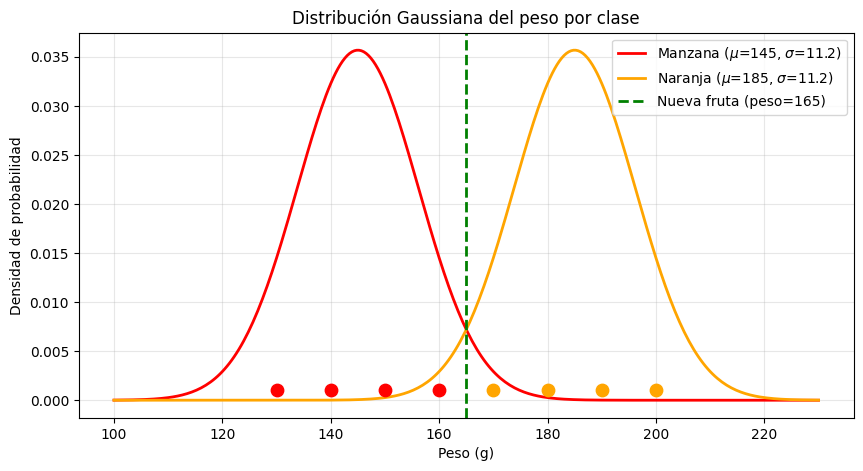

P(peso=165 | Manzana) = 0.007204
P(peso=165 | Naranja)  = 0.007204


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

# Datos
pesos_manzana = np.array([130, 140, 150, 160])
pesos_naranja = np.array([170, 180, 190, 200])

# Parámetros
mu_m, sigma_m = pesos_manzana.mean(), pesos_manzana.std()
mu_n, sigma_n = pesos_naranja.mean(), pesos_naranja.std()

x_range = np.linspace(100, 230, 300)

plt.figure(figsize=(10, 5))
plt.plot(x_range, norm.pdf(x_range, mu_m, sigma_m), 'r-', linewidth=2,
         label=f'Manzana ($\mu$={mu_m:.0f}, $\sigma$={sigma_m:.1f})')
plt.plot(x_range, norm.pdf(x_range, mu_n, sigma_n), color='orange', linewidth=2,
         label=f'Naranja ($\mu$={mu_n:.0f}, $\sigma$={sigma_n:.1f})')

# Marcar el punto nuevo
x_test = 165
plt.axvline(x=x_test, color='green', linestyle='--', linewidth=2, label=f'Nueva fruta (peso={x_test})')
plt.scatter(pesos_manzana, [0.001]*len(pesos_manzana), color='red', s=80, zorder=5)
plt.scatter(pesos_naranja, [0.001]*len(pesos_naranja), color='orange', s=80, zorder=5)

plt.xlabel('Peso (g)')
plt.ylabel('Densidad de probabilidad')
plt.title('Distribución Gaussiana del peso por clase')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print(f"P(peso=165 | Manzana) = {norm.pdf(x_test, mu_m, sigma_m):.6f}")
print(f"P(peso=165 | Naranja)  = {norm.pdf(x_test, mu_n, sigma_n):.6f}")

### Paso 4: Trabajar en escala logarítmica

En la práctica, multiplicar muchas probabilidades pequeñas causa **underflow numérico** (números tan pequeños que la computadora los redondea a 0). La solución es trabajar con **logaritmos**:

$$
\log P(y = c \ | \ \mathbf{x}) \propto \log P(y = c) + \sum_{j=1}^{n} \log P(x_j \ | \ y = c)
$$

Como el logaritmo es una función monótona creciente, el $\arg\max$ no cambia:

$$
\hat{y} = \arg\max_c \left[ \log P(y = c) + \sum_{j=1}^{n} \log P(x_j \ | \ y = c) \right]
$$

Sustituyendo la Gaussiana y simplificando:

$$
\log P(x_j \ | \ y = c) = -\frac{1}{2}\log(2\pi\sigma_{cj}^2) - \frac{(x_j - \mu_{cj})^2}{2\sigma_{cj}^2}
$$

Esto es exactamente lo que implementa el código: **sumamos log-probabilidades en lugar de multiplicar probabilidades**.

### Resumen del algoritmo

**Entrenamiento** (solo calcula estadísticas):
1. Para cada clase $c$, calcular:
   - **Prior**: $P(y = c) = \frac{n_c}{n}$ (proporción de muestras)
   - **Media** de cada feature: $\mu_{cj}$
   - **Varianza** de cada feature: $\sigma_{cj}^2$

**Predicción** (para un nuevo punto $\mathbf{x}$):
1. Para cada clase $c$, calcular el **log-posterior**:

$$
\text{score}_c = \log P(y = c) + \sum_{j=1}^{n} \log P(x_j \ | \ y = c)
$$

2. Retornar la clase con el mayor score:

$$
\hat{y} = \arg\max_c \ \text{score}_c
$$

### Ejemplo numérico

Usemos nuestro dataset de frutas para clasificar una nueva fruta con **peso = 165 g** y **diámetro = 7.8 cm**.

| Peso (g) | Diámetro (cm) | Fruta    |
|----------|---------------|----------|
| 130      | 7.0           | Manzana (0) |
| 140      | 7.2           | Manzana (0) |
| 150      | 7.4           | Manzana (0) |
| 160      | 7.6           | Manzana (0) |
| 170      | 8.0           | Naranja (1) |
| 180      | 8.5           | Naranja (1) |
| 190      | 9.0           | Naranja (1) |
| 200      | 9.2           | Naranja (1) |

**Paso 1: Calcular priors**

$$
P(\text{Manzana}) = \frac{4}{8} = 0.5 \qquad P(\text{Naranja}) = \frac{4}{8} = 0.5
$$

**Paso 2: Calcular media y varianza por clase y feature**

| Parámetro | Peso (Manzana) | Peso (Naranja) | Diámetro (Manzana) | Diámetro (Naranja) |
|-----------|----------------|----------------|--------------------|--------------------|  
| $\mu$     | 145.0          | 185.0          | 7.30               | 8.675              |
| $\sigma^2$| 125.0          | 125.0          | 0.045              | 0.2169             |

**Paso 3: Calcular likelihoods para $\mathbf{x} = (165, 7.8)$**

Para **Manzana** (peso):

$$
P(165 \ | \ \text{Manzana}) = \frac{1}{\sqrt{2\pi \cdot 125}} \exp\left(-\frac{(165-145)^2}{2 \cdot 125}\right) = \frac{1}{28.02} \exp(-1.6) \approx 0.0072
$$

Para **Naranja** (peso):

$$
P(165 \ | \ \text{Naranja}) = \frac{1}{\sqrt{2\pi \cdot 125}} \exp\left(-\frac{(165-185)^2}{2 \cdot 125}\right) = \frac{1}{28.02} \exp(-1.6) \approx 0.0072
$$

Para **Manzana** (diámetro):

$$
P(7.8 \ | \ \text{Manzana}) = \frac{1}{\sqrt{2\pi \cdot 0.045}} \exp\left(-\frac{(7.8-7.3)^2}{2 \cdot 0.045}\right) \approx 0.0081
$$

Para **Naranja** (diámetro):

$$
P(7.8 \ | \ \text{Naranja}) = \frac{1}{\sqrt{2\pi \cdot 0.2169}} \exp\left(-\frac{(7.8-8.675)^2}{2 \cdot 0.2169}\right) \approx 0.0879
$$

**Paso 4: Calcular log-posteriors**

$$
\text{score}_{\text{Manzana}} = \log(0.5) + \log(0.0072) + \log(0.0081) \approx -0.693 + (-4.934) + (-4.816) = -10.443
$$

$$
\text{score}_{\text{Naranja}} = \log(0.5) + \log(0.0072) + \log(0.0879) \approx -0.693 + (-4.934) + (-2.432) = -8.059
$$

**Paso 5: Decidir**

$$
-8.059 > -10.443 \implies \boxed{\hat{y} = \text{Naranja (1)}}
$$

Aunque ambas clases tienen el mismo likelihood para el peso (el punto está equidistante), el **diámetro** marca la diferencia: 7.8 cm es más probable para una naranja que para una manzana.

In [3]:
import numpy as np

# Datos
X = np.array([[130, 7.0], [140, 7.2], [150, 7.4], [160, 7.6],
              [170, 8.0], [180, 8.5], [190, 9.0], [200, 9.2]])
y = np.array([0, 0, 0, 0, 1, 1, 1, 1])
x_new = np.array([165, 7.8])

print("=== Ejemplo numérico: Naive Bayes paso a paso ===")

for c, nombre in [(0, 'Manzana'), (1, 'Naranja')]:
    X_c = X[y == c]
    prior = len(X_c) / len(X)
    mean = X_c.mean(axis=0)
    var = X_c.var(axis=0)

    print(f"\nClase {nombre} (y={c}):")
    print(f"  Prior: P({nombre}) = {prior}")
    print(f"  Media: μ = {mean}")
    print(f"  Varianza: σ² = {var}")

    # Calcular PDF para cada feature
    log_posterior = np.log(prior)
    for j, feat_name in enumerate(['Peso', 'Diámetro']):
        pdf_val = (1 / np.sqrt(2 * np.pi * var[j])) * np.exp(-((x_new[j] - mean[j])**2) / (2 * var[j]))
        log_pdf = np.log(pdf_val)
        log_posterior += log_pdf
        print(f"  P({feat_name}={x_new[j]} | {nombre}) = {pdf_val:.6f}  →  log = {log_pdf:.4f}")

    print(f"  Log-posterior total = {log_posterior:.4f}")

print(f"\n→ Clase predicha: Naranja (1) tiene mayor log-posterior")

=== Ejemplo numérico: Naive Bayes paso a paso ===

Clase Manzana (y=0):
  Prior: P(Manzana) = 0.5
  Media: μ = [145.    7.3]
  Varianza: σ² = [1.25e+02 5.00e-02]
  P(Peso=165.0 | Manzana) = 0.007204  →  log = -4.9331
  P(Diámetro=7.8 | Manzana) = 0.146450  →  log = -1.9211
  Log-posterior total = -7.5473

Clase Naranja (y=1):
  Prior: P(Naranja) = 0.5
  Media: μ = [185.      8.675]
  Varianza: σ² = [125.         0.216875]
  P(Peso=165.0 | Naranja) = 0.007204  →  log = -4.9331
  P(Diámetro=7.8 | Naranja) = 0.146629  →  log = -1.9199
  Log-posterior total = -7.5461

→ Clase predicha: Naranja (1) tiene mayor log-posterior


## Implementación con Código

### Funciones

In [4]:
import numpy as np

def gaussian_pdf(x, mean, var):
    """Calcula la densidad de probabilidad Gaussiana"""
    numerator = np.exp(-((x - mean) ** 2) / (2 * var))
    denominator = np.sqrt(2 * np.pi * var)
    return numerator / denominator

def naive_bayes_fit(X, y):
    """Calcula media, varianza y prior para cada clase"""
    n_samples, n_features = X.shape
    classes = np.unique(y)
    n_classes = len(classes)

    mean = np.zeros((n_classes, n_features), dtype=np.float64)
    var = np.zeros((n_classes, n_features), dtype=np.float64)
    priors = np.zeros(n_classes, dtype=np.float64)

    for idx, c in enumerate(classes):
        X_c = X[y == c]
        mean[idx, :] = X_c.mean(axis=0)
        var[idx, :] = X_c.var(axis=0)
        priors[idx] = X_c.shape[0] / float(n_samples)

    return classes, mean, var, priors

def naive_bayes_predict(X, classes, mean, var, priors):
    """Predice la clase para cada punto en X"""
    y_pred = []
    for x in X:
        posteriors = []
        for idx, c in enumerate(classes):
            prior = np.log(priors[idx])
            likelihood = np.sum(np.log(gaussian_pdf(x, mean[idx], var[idx])))
            posterior = prior + likelihood
            posteriors.append(posterior)
        y_pred.append(classes[np.argmax(posteriors)])
    return np.array(y_pred)

In [5]:
from sklearn.model_selection import train_test_split
from sklearn import datasets

# Generar datos
X, y = datasets.make_classification(
    n_samples=1000, n_features=10, n_classes=2, random_state=123
)

# Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123
)

# Entrenar
classes, mean, var, priors = naive_bayes_fit(X_train, y_train)

# Predecir y evaluar
predictions = naive_bayes_predict(X_test, classes, mean, var, priors)
accuracy = np.sum(y_test == predictions) / len(y_test)
print(f"Naive Bayes accuracy: {accuracy:.4f}")

Naive Bayes accuracy: 0.9650


### Clase

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


class NaiveBayes:
    def fit(self, X, y):
        """Calcula media, varianza y prior para cada clase"""
        n_samples, n_features = X.shape
        self._classes = np.unique(y)
        n_classes = len(self._classes)

        # Calcular media, varianza y prior para cada clase
        self._mean = np.zeros((n_classes, n_features), dtype=np.float64)
        self._var = np.zeros((n_classes, n_features), dtype=np.float64)
        self._priors = np.zeros(n_classes, dtype=np.float64)

        for idx, c in enumerate(self._classes):
            X_c = X[y == c]
            self._mean[idx, :] = X_c.mean(axis=0)
            self._var[idx, :] = X_c.var(axis=0)
            self._priors[idx] = X_c.shape[0] / float(n_samples)

    def predict(self, X):
        """Predice la clase para cada punto en X"""
        y_pred = [self._predict(x) for x in X]
        return np.array(y_pred)

    def _predict(self, x):
        """Predice la clase de un solo punto"""
        posteriors = []
        # Calcular log-posterior para cada clase
        for idx, c in enumerate(self._classes):
            prior = np.log(self._priors[idx])
            posterior = np.sum(np.log(self._pdf(idx, x)))
            posterior = prior + posterior
            posteriors.append(posterior)
        # Retornar clase con mayor log-posterior
        return self._classes[np.argmax(posteriors)]

    def _pdf(self, class_idx, x):
        """Densidad de probabilidad Gaussiana"""
        mean = self._mean[class_idx]
        var = self._var[class_idx]
        numerator = np.exp(-((x - mean) ** 2) / (2 * var))
        denominator = np.sqrt(2 * np.pi * var)
        return numerator / denominator

    def score(self, X, y):
        """Calcula la accuracy del modelo"""
        predictions = self.predict(X)
        return np.sum(predictions == y) / len(y)

    def plot_distributions(self, X, y, feature_idx=0, feature_name="Feature"):
        """Grafica las distribuciones Gaussianas aprendidas para una feature"""
        plt.figure(figsize=(10, 5))
        colors = ['blue', 'red', 'green', 'purple', 'orange']

        x_range = np.linspace(X[:, feature_idx].min() - 1, X[:, feature_idx].max() + 1, 300)

        for idx, c in enumerate(self._classes):
            mean = self._mean[idx, feature_idx]
            var = self._var[idx, feature_idx]
            std = np.sqrt(var)
            pdf_vals = (1 / np.sqrt(2 * np.pi * var)) * np.exp(-((x_range - mean)**2) / (2 * var))

            color = colors[idx % len(colors)]
            plt.plot(x_range, pdf_vals, color=color, linewidth=2,
                     label=f'Clase {c} ($\mu$={mean:.2f}, $\sigma$={std:.2f})')
            plt.fill_between(x_range, pdf_vals, alpha=0.1, color=color)

            # Datos reales
            X_c = X[y == c]
            plt.scatter(X_c[:, feature_idx], [0.001]*len(X_c), color=color, s=30, alpha=0.5)

        plt.xlabel(feature_name)
        plt.ylabel('Densidad de probabilidad')
        plt.title(f'Distribuciones Gaussianas aprendidas - {feature_name}')
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.show()

    def plot_decision_boundary(self, X, y, title="Frontera de decisión Naive Bayes", feature_indices=(0, 1)):
        """Grafica la frontera de decisión usando dos features"""
        i, j = feature_indices
        X_2d = X[:, [i, j]]

        # Reentrenar con solo 2 features para la visualización
        temp_nb = NaiveBayes()
        temp_nb.fit(X_2d, y)

        h = 0.1
        x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
        y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
        xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                             np.arange(y_min, y_max, h))

        Z = temp_nb.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)

        cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
        cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

        plt.figure(figsize=(8, 6))
        plt.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_light)
        plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap=cmap_bold, edgecolors='k', s=60)
        plt.xlabel(f'Feature {i}')
        plt.ylabel(f'Feature {j}')
        plt.title(title)
        plt.grid(True, alpha=0.3)
        plt.show()

Naive Bayes accuracy: 0.9650


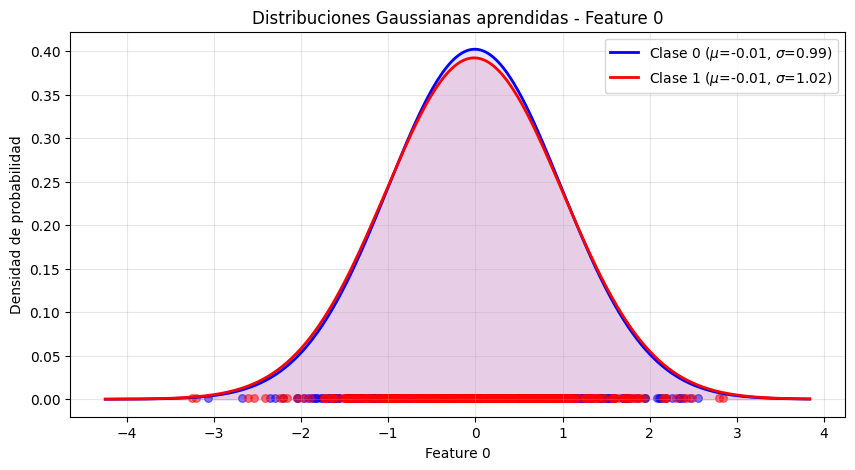

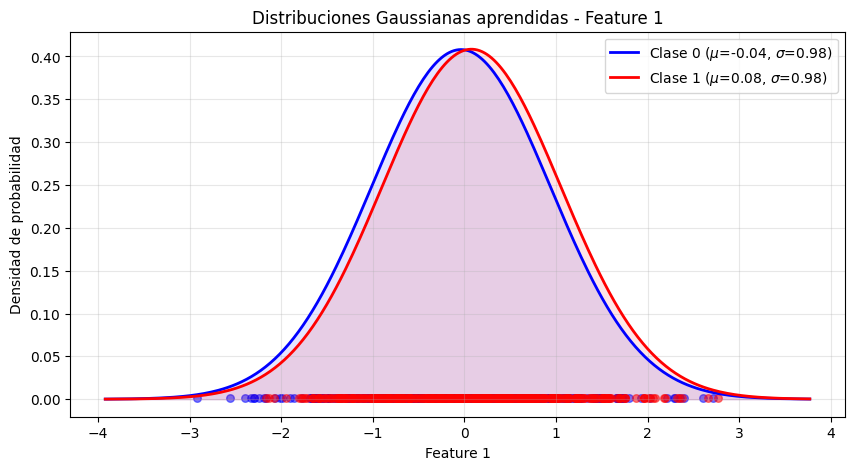

In [7]:
from sklearn.model_selection import train_test_split
from sklearn import datasets

# Generar datos
X, y = datasets.make_classification(
    n_samples=1000, n_features=10, n_classes=2, random_state=123
)

# Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123
)

# Crear y entrenar modelo
model = NaiveBayes()
model.fit(X_train, y_train)

# Evaluar
acc = model.score(X_test, y_test)
print(f"Naive Bayes accuracy: {acc:.4f}")

# Visualizar distribuciones de las 2 primeras features
model.plot_distributions(X_train, y_train, feature_idx=0, feature_name="Feature 0")
model.plot_distributions(X_train, y_train, feature_idx=1, feature_name="Feature 1")

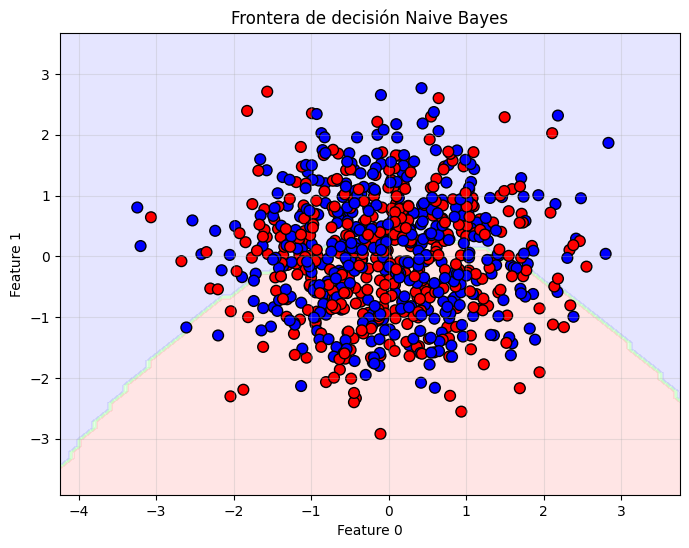

In [8]:
# Visualizar frontera de decisión
model.plot_decision_boundary(X_train, y_train)

Naive Bayes accuracy en Iris (3 clases): 0.9667


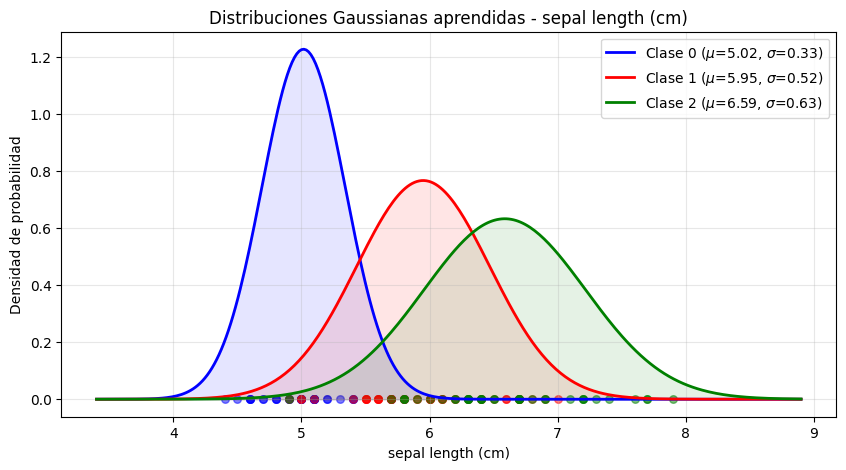

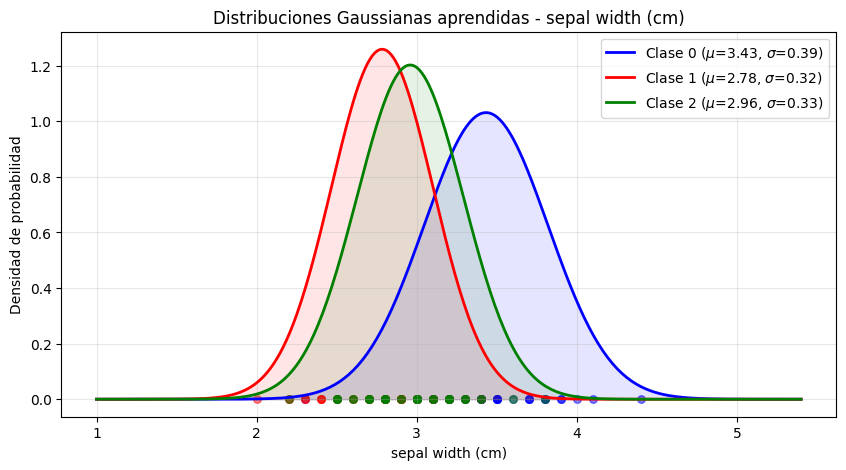

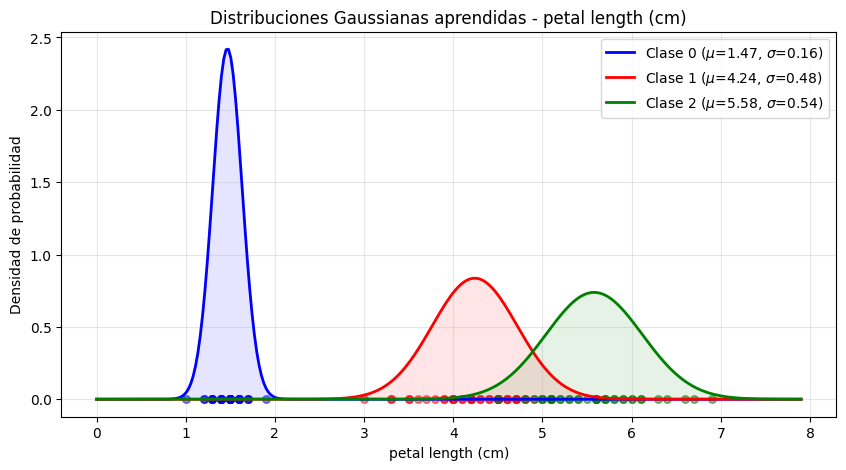

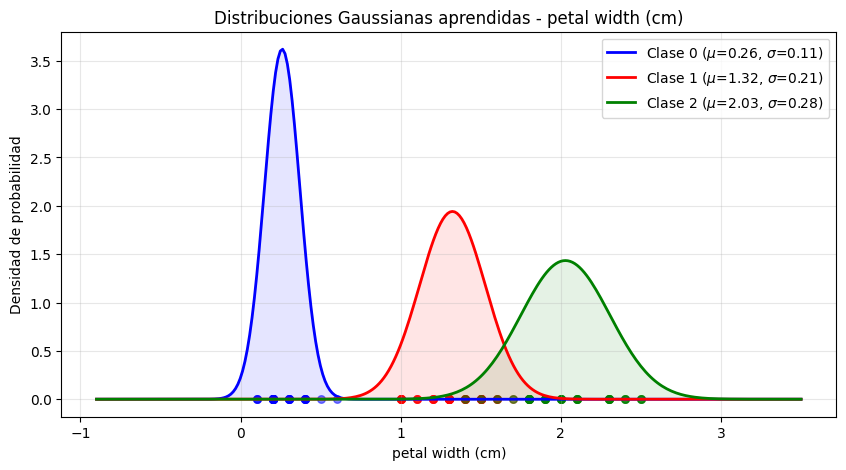

In [9]:
# Probar con el dataset Iris (3 clases)
iris = datasets.load_iris()
X_iris, y_iris = iris.data, iris.target

X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris, y_iris, test_size=0.2, random_state=123
)

model_iris = NaiveBayes()
model_iris.fit(X_train_iris, y_train_iris)
acc_iris = model_iris.score(X_test_iris, y_test_iris)
print(f"Naive Bayes accuracy en Iris (3 clases): {acc_iris:.4f}")

# Visualizar distribuciones por feature del Iris
for i, name in enumerate(iris.feature_names):
    model_iris.plot_distributions(X_train_iris, y_train_iris, feature_idx=i, feature_name=name)